In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import matplotlib.colors as mcolors
import math
import scipy
from tof_helper_functions.tof_framework import RawTOFPointList, RebinnedTOFPointList

In [4]:
# Load data from dumbs
source_dir = "cascadeTof"

rawdata = pd.read_csv(source_dir+"/TOF_rawdata_dumb.csv", sep='\t')
rawdata_bin = rawdata["Unnamed: 0"]
rawdata_s631 = rawdata["Raw counts [counts/bin]  631 mm tube"]
rawdata_s460 = rawdata["Raw counts [counts/bin] 460 mm tube"]

processeddata = pd.read_csv(source_dir+"/TOF_processed_dumb.csv", sep='\t')
v_s631 = processeddata["v [m/s] 631 mm tube"]
v_s460 = processeddata["v [m/s] 460 mm tube"]
pdata_s631 = processeddata["Processed counts [counts/(m/s)] 631 mm tube"]
pdata_s460 = processeddata["Processed counts [counts/(m/s)] 460 mm tube"]

rebinneddata = pd.read_csv(source_dir+"/TOF_rebinned_dumb.csv", sep='\t')
v_rebinned = rebinneddata["v [m/s]"]
rdata_s631 = rebinneddata["Counts [counts/(m/s)] 631 mm tube"]
rdata_s460 = rebinneddata["Counts [counts/(m/s)] 460 mm tube"]
rdata_s631_err = rebinneddata["Counts error [counts/(m/s)] 631 mm tube"]
rdata_s460_err = rebinneddata["Counts error [counts/(m/s)] 460 mm tube"]

# Scalar data from past analysis
darkcounts_s631 =      36.5696969
darkcounts_s631_err =   0.3602967
darkcounts_s460 =      34.1606060
darkcounts_s460_err =   0.3310645

No values to rebin from in the interval [18.85;18.900000000000002[ m/s
No values to rebin from in the interval [19.25;19.3[ m/s
No values to rebin from in the interval [19.55;19.6[ m/s
No values to rebin from in the interval [19.85;19.900000000000002[ m/s
No values to rebin from in the interval [15.600000000000001;15.650000000000002[ m/s
No values to rebin from in the interval [16.25;16.3[ m/s
No values to rebin from in the interval [16.6;16.650000000000002[ m/s
No values to rebin from in the interval [16.9;16.95[ m/s
No values to rebin from in the interval [17.15;17.2[ m/s
No values to rebin from in the interval [17.4;17.45[ m/s
No values to rebin from in the interval [17.6;17.650000000000002[ m/s
No values to rebin from in the interval [17.8;17.85[ m/s
No values to rebin from in the interval [18.15;18.2[ m/s
No values to rebin from in the interval [18.3;18.35[ m/s
No values to rebin from in the interval [18.5;18.55[ m/s
No values to rebin from in the interval [18.65;18.7[ m/s
No valu

Text(0.5, 1.0, 'Rebinned TOF spectra for delta_t = 24.0 ms')

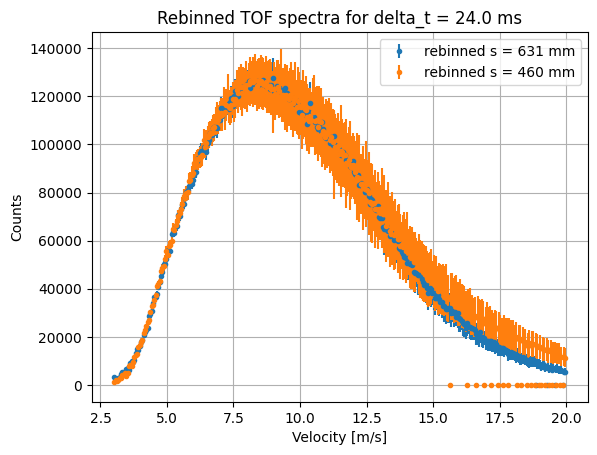

In [5]:
delta_t = 24.0
v_max = 20.0
v_min = 3.0
v_step = 0.05
convolution_t = 5.0
convolution_t_err = 4.0

rawTOF_s631 = RawTOFPointList(rawdata_s631, 
                         s=631, 
                         label = "s = 631 mm", 
                         darkcounts=darkcounts_s631,
                         darkcounts_err=darkcounts_s631_err,
                         delta_t=delta_t,
                         delta_t_err=0.0,
                         convolution_t=convolution_t,
                         convolution_t_err=convolution_t_err)

rebinnedTOF_s631 = RebinnedTOFPointList(rawTOF_s631,
                                   v_min = v_min,
                                   v_max = v_max,
                                   v_step = v_step,
                                   label = "rebinned s = 631 mm")

rawTOF_s460 = RawTOFPointList(rawdata_s460, 
                         s=460, 
                         label = "s = 460 mm", 
                         darkcounts=darkcounts_s460,
                         darkcounts_err=darkcounts_s460_err,
                         delta_t=delta_t,
                         delta_t_err=0.0,
                         convolution_t=convolution_t,
                         convolution_t_err=convolution_t_err)

rebinnedTOF_s460 = RebinnedTOFPointList(rawTOF_s460,
                                   v_min = v_min,
                                   v_max = v_max,
                                   v_step = v_step,
                                   label = "rebinned s = 460 mm")


plt.errorbar(rebinnedTOF_s631.v, rebinnedTOF_s631.N_v, rebinnedTOF_s631.N_v_err, label= rebinnedTOF_s631.label, fmt='.')
plt.errorbar(rebinnedTOF_s460.v, rebinnedTOF_s460.N_v, rebinnedTOF_s460.N_v_err, label= rebinnedTOF_s460.label, fmt='.')
plt.xlabel("Velocity [m/s]")
plt.ylabel("Counts")
plt.grid(True)
plt.legend()
plt.title(f"Rebinned TOF spectra for delta_t = {delta_t} ms")

In [6]:
# chi squared, or some other (at this point I don't care anymore) test
delta_t_min, delta_t_max, delta_t_n = 20.0, 28.0, 150
delta_t_list = np.linspace(delta_t_min, delta_t_max, delta_t_n)

v_max = 12.0
v_min = 6.0
v_step = 0.05
convolution_t = 5.0
convolution_t_err = 4.0

chisqr = []
for delta_t in delta_t_list:
    rawTOF_s631 = RawTOFPointList(rawdata_s631, 
                            s=631, 
                            label = "s = 631 mm", 
                            darkcounts=darkcounts_s631,
                            darkcounts_err=darkcounts_s631_err,
                            delta_t=delta_t,
                            delta_t_err=0.0,
                            convolution_t=convolution_t,
                            convolution_t_err=convolution_t_err)

    rebinnedTOF_s631 = RebinnedTOFPointList(rawTOF_s631,
                                    v_min = v_min,
                                    v_max = v_max,
                                    v_step = v_step,
                                    label = "rebinned s = 631 mm")

    rawTOF_s460 = RawTOFPointList(rawdata_s460, 
                            s=460, 
                            label = "s = 460 mm", 
                            darkcounts=darkcounts_s460,
                            darkcounts_err=darkcounts_s460_err,
                            delta_t=delta_t,
                            delta_t_err=0.0,
                            convolution_t=convolution_t,
                            convolution_t_err=convolution_t_err)

    rebinnedTOF_s460 = RebinnedTOFPointList(rawTOF_s460,
                                    v_min = v_min,
                                    v_max = v_max,
                                    v_step = v_step,
                                    label = "rebinned s = 460 mm")

    data = np.array(rebinnedTOF_s631.N_v)
    model = np.array(rebinnedTOF_s460.N_v)
    data_err = np.array(rebinnedTOF_s631.N_v_err)
    model_err = np.array(rebinnedTOF_s460.N_v_err)

    chisqr.append( np.sum( (data-model)**2 / (model_err**2 + data_err**2)) )








Popt
[24.16724048  1.58642341  5.60183466]
Pcov
[[ 1.27891403e-04 -3.06016548e-05  9.83925669e-05]
 [-3.06016548e-05  2.90283666e-04 -1.56084141e-03]
 [ 9.83925669e-05 -1.56084141e-03  1.52108536e-02]]
perr
[0.01130891 0.01703771 0.12333229]


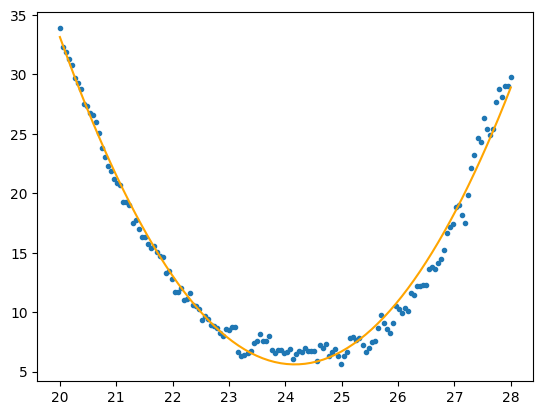

In [7]:
def quadratic_func(x, c, a, d, k=0):
    return a * (x-c)**2 + k * (x-c) + d

# making an initial guess
a0 = 10
k0 = 0.0
d0 = 100  
c0 = 29.0

p0 = [c0, a0, d0]

popt, pcov = scipy.optimize.curve_fit(quadratic_func, xdata=delta_t_list, ydata=chisqr, p0=p0)
perr = np.sqrt(np.diag(pcov)) # errors

print('Popt')
print(popt)
print('Pcov')
print(pcov)
print('perr')
print(perr)

plt.scatter(delta_t_list, chisqr, marker='.')
plt.plot(delta_t_list, quadratic_func(delta_t_list, *popt), label="fit", color='orange')